# PyZX proti Qiskit: primerjava optimizatorjev T-vrat

Eksperiment: na naključnih vezjih primerjamo optimizatorje Qiskit, PyZX in njuni kombinaciji.
Metrike: število T-vrat, skupno število vrat, število dvokubitnih vrat in čas izvajanja.

Struktura zvezka:
1. Uvozi in parametri
2. Pomožne funkcije
3. Izvedba eksperimenta in shranjevanje rezultatov
4. Nalaganje rezultatov in grafi (vsak graf v svoji celici, ponovna izvedba eksperimenta ni potrebna)

## 1. Uvozi

In [8]:
import csv
import json
import os
import platform
import random
import time
from datetime import datetime

import matplotlib.pyplot as plt
import numpy as np
import pyzx as zx
import qiskit
from qiskit import QuantumCircuit, qasm2, transpile
from scipy import stats

from qcGenerator import QuantumCircuitGenerator
from pxOptimizer import PyZXOptimizer
from qiskitOptimizer import CLIFFORD_T_BASIS, QiskitOptimizer
from mixOptimizers import PyZXThenQiskitOptimizer, QiskitThenPyZXOptimizer

## 2. Parametri

In [9]:
# Seme: vsa naključnost (generator vezij) je določena s tem semenom, zato je eksperiment ponovljiv
seed = 0

# Preiskava po številu kubitov (fiksna globina)
benchmark_qubit_counts = [5, 10, 15, 20, 25]
benchmark_depth = 100

# Preiskava po globini (fiksno število kubitov)
depth_sweep_depths = [25, 50, 100, 150, 200]
depth_sweep_qubits = 10

circuits_per_size = 10
qiskit_level = 3

run_dir = None
results_root = "results"

display_names = {"Original": "Izvirno vezje", "Qiskit only": "Samo Qiskit", "PyZX only": "Samo PyZX",
                 "Qiskit -> PyZX": "Qiskit -> PyZX", "PyZX -> Qiskit": "PyZX -> Qiskit"}

## 3. Eksperiment

In [10]:
optimizers = {
    "Qiskit only": QiskitOptimizer(optimization_level=qiskit_level),
    "PyZX only": PyZXOptimizer(),
    "Qiskit -> PyZX": QiskitThenPyZXOptimizer(optimization_level=qiskit_level),
    "PyZX -> Qiskit": PyZXThenQiskitOptimizer(),  
}
methods = ["Original"] + list(optimizers)
# circuit_depth = globina vezja po razgradnji v Clifford+T (ne mešati s parametrom "depth" generatorja)
metrics = ["t_count", "clifford_gates", "total_gates", "two_qubit_gates", "circuit_depth", "t_removed",
           "time_s", "time_per_qubit_s", "time_per_depth_s",
           "t_reduction_pct", "t_reduction_pct_per_qubit", "t_reduction_pct_per_depth"]


def gate_metrics(qc: QuantumCircuit) -> dict:
    decomposed = transpile(qc, basis_gates=CLIFFORD_T_BASIS, optimization_level=0)
    ops = decomposed.count_ops()
    total = sum(ops.values())
    t_count = ops.get("t", 0) + ops.get("tdg", 0)
    return {
        "total_gates": total,
        "t_count": t_count,
        "clifford_gates": total - t_count,  # baza je Clifford+T, vse razen T/Tdg je Cliffordovo vrata
        "two_qubit_gates": ops.get("cx", 0),
        "circuit_depth": decomposed.depth(),
    }


def file_name(method: str) -> str:
    return method.lower().replace(" -> ", "_then_").replace(" ", "_") + ".qasm"


def ratio_metrics(time_s: float, t_reduction_pct: float, n: int, d: int) -> dict:
    # d je parameter globine generatorja (število plasti vrat)
    return {
        "time_per_qubit_s": time_s / n,
        "time_per_depth_s": time_s / d,
        "t_reduction_pct": t_reduction_pct,
        "t_reduction_pct_per_qubit": t_reduction_pct / n,
        "t_reduction_pct_per_depth": t_reduction_pct / d,
    }


def mean_std_ci(values: list) -> tuple:
    # povprečje, vzorčni standardni odklon (ddof=1) in polovična širina 95 % intervala zaupanja (Studentov t)
    v = np.asarray(values, dtype=float)
    if len(v) < 2:
        return float(v.mean()), 0.0, 0.0
    std = float(v.std(ddof=1))
    return float(v.mean()), std, float(stats.t.ppf(0.975, len(v) - 1) * std / np.sqrt(len(v)))


def build_summary(runs: list) -> list:
    summary = []
    for sweep, points in (("qubits", benchmark_qubit_counts), ("depth", depth_sweep_depths)):
        for x in points:
            for method in methods:
                rows = [r for r in runs if r["sweep"] == sweep and r[sweep] == x and r["method"] == method]
                entry = {"sweep": sweep, "qubits": rows[0]["qubits"], "depth": rows[0]["depth"], "method": method}
                for m in metrics:
                    entry[f"mean_{m}"], entry[f"std_{m}"], entry[f"ci95_{m}"] = mean_std_ci([r[m] for r in rows])
                summary.append(entry)
    return summary


def save_results(run_dir: str, parameters: dict, summary: list, runs: list):
    with open(os.path.join(run_dir, "results.json"), "w") as f:
        json.dump({"parameters": parameters, "summary": summary, "runs": runs}, f, indent=2)
    for file, rows in (("summary.csv", summary), ("runs.csv", runs)):
        with open(os.path.join(run_dir, file), "w", newline="") as f:
            writer = csv.DictWriter(f, fieldnames=rows[0].keys())
            writer.writeheader()
            writer.writerows(rows)


def benchmark_circuit(sweep: str, n: int, d: int, i: int, circuit_seed: int, circuit_dir: str) -> list:
    random.seed(circuit_seed)
    circuit = QuantumCircuitGenerator(num_qubits=n, depth=d).generate()
    os.makedirs(circuit_dir, exist_ok=True)
    qasm2.dump(circuit, os.path.join(circuit_dir, "original.qasm"))
    original = gate_metrics(circuit)
    base = {"sweep": sweep, "qubits": n, "depth": d, "circuit": i, "seed": circuit_seed}
    rows = [{**base, "method": "Original", "time_s": 0.0, "t_removed": 0, **original,
             **ratio_metrics(0.0, 0.0, n, d)}]

    for name, optimizer in optimizers.items():
        # time_s je samo optimizacija, brez shranjevanja
        start = time.perf_counter()
        optimized = optimizer.optimize(circuit)
        elapsed = time.perf_counter() - start
        qasm2.dump(optimized, os.path.join(circuit_dir, file_name(name)))
        optimized_metrics = gate_metrics(optimized)
        t_reduction_pct = (100 * (original["t_count"] - optimized_metrics["t_count"]) / original["t_count"]
                           if original["t_count"] else 0.0)
        rows.append({**base, "method": name, "time_s": elapsed,
                     "t_removed": original["t_count"] - optimized_metrics["t_count"],
                     **optimized_metrics, **ratio_metrics(elapsed, t_reduction_pct, n, d)})
    return rows


def add_missing_metrics(runs: list, run_dir: str) -> bool:
    # starejši zagoni nimajo globine vezja, Cliffordovih vrat in t_removed: izračunamo jih iz shranjenih .qasm
    new_keys = ("circuit_depth", "clifford_gates", "t_removed")
    if all(k in r for r in runs for k in new_keys):
        return False
    mismatches = 0
    for r in runs:
        circuit_dir = os.path.join(run_dir, f"{r['sweep']}_{r[r['sweep']]}", f"circuit_{r['circuit']:02d}")
        name = "original.qasm" if r["method"] == "Original" else file_name(r["method"])
        recomputed = gate_metrics(QuantumCircuit.from_qasm_file(os.path.join(circuit_dir, name)))
        mismatches += recomputed["t_count"] != r["t_count"]
        r["circuit_depth"], r["clifford_gates"] = recomputed["circuit_depth"], recomputed["clifford_gates"]
    t_original = {(r["sweep"], r["qubits"], r["depth"], r["circuit"]): r["t_count"]
                  for r in runs if r["method"] == "Original"}
    for r in runs:
        r["t_removed"] = t_original[(r["sweep"], r["qubits"], r["depth"], r["circuit"])] - r["t_count"]
    if mismatches:
        print(f"Opozorilo: pri {mismatches} vezjih se T-count iz .qasm razlikuje od shranjenega")
    return True

In [4]:
# Ena mapa na število kubitov in na globino, ena podmapa na vezje
run_dir = os.path.join(results_root, datetime.now().strftime("%Y-%m-%d_%H-%M-%S"))
runs = []
benchmark_start = time.perf_counter()

for n in benchmark_qubit_counts:
    for i in range(circuits_per_size):
        runs += benchmark_circuit("qubits", n, benchmark_depth, i, seed + n * 1000 + i,
                                  os.path.join(run_dir, f"qubits_{n}", f"circuit_{i:02d}"))
        print(f"kubiti {n}: vezje {i + 1}/{circuits_per_size} "
              f"({(time.perf_counter() - benchmark_start) / 60:.1f} min)")

for d in depth_sweep_depths:
    for i in range(circuits_per_size):
        runs += benchmark_circuit("depth", depth_sweep_qubits, d, i, seed + 1_000_000 + d * 1000 + i,
                                  os.path.join(run_dir, f"depth_{d}", f"circuit_{i:02d}"))
        print(f"globina {d}: vezje {i + 1}/{circuits_per_size} "
              f"({(time.perf_counter() - benchmark_start) / 60:.1f} min)")

total_runtime_min = (time.perf_counter() - benchmark_start) / 60

kubiti 5: vezje 1/10 (0.1 min)
kubiti 5: vezje 2/10 (0.2 min)
kubiti 5: vezje 3/10 (0.3 min)
kubiti 5: vezje 4/10 (0.4 min)
kubiti 5: vezje 5/10 (0.5 min)
kubiti 5: vezje 6/10 (0.6 min)
kubiti 5: vezje 7/10 (0.8 min)
kubiti 5: vezje 8/10 (0.9 min)
kubiti 5: vezje 9/10 (1.0 min)
kubiti 5: vezje 10/10 (1.2 min)
kubiti 10: vezje 1/10 (1.6 min)
kubiti 10: vezje 2/10 (2.0 min)
kubiti 10: vezje 3/10 (2.6 min)
kubiti 10: vezje 4/10 (3.0 min)
kubiti 10: vezje 5/10 (3.4 min)
kubiti 10: vezje 6/10 (3.8 min)
kubiti 10: vezje 7/10 (4.2 min)
kubiti 10: vezje 8/10 (4.7 min)
kubiti 10: vezje 9/10 (5.1 min)
kubiti 10: vezje 10/10 (5.6 min)
kubiti 15: vezje 1/10 (6.9 min)
kubiti 15: vezje 2/10 (8.1 min)
kubiti 15: vezje 3/10 (9.6 min)
kubiti 15: vezje 4/10 (10.8 min)
kubiti 15: vezje 5/10 (12.2 min)
kubiti 15: vezje 6/10 (13.4 min)
kubiti 15: vezje 7/10 (14.6 min)
kubiti 15: vezje 8/10 (15.7 min)
kubiti 15: vezje 9/10 (16.8 min)
kubiti 15: vezje 10/10 (18.7 min)
kubiti 20: vezje 1/10 (20.6 min)
kubiti 

### Povzetek in shranjevanje rezultatov

In [ ]:
summary = build_summary(runs)

parameters = {
    "seed": seed,
    "qubit_sweep": {"qubit_counts": benchmark_qubit_counts, "depth": benchmark_depth,
                    "seed_formula": "seed + qubits * 1000 + circuit_index"},
    "depth_sweep": {"depths": depth_sweep_depths, "qubits": depth_sweep_qubits,
                    "seed_formula": "seed + 1000000 + depth * 1000 + circuit_index"},
    "circuits_per_size": circuits_per_size,
    "depth_meaning": "generator depth parameter (number of gate layers)",
    "circuit_depth_meaning": "circuit depth after decomposition to the Clifford+T basis (qiskit QuantumCircuit.depth())",
    "clifford_gates_meaning": "total gates in the Clifford+T basis minus T and Tdg gates",
    "t_reduction_pct_formula": "100 * (original T-count - optimized T-count) / original T-count",
    "summary_statistics": "mean_*, std_* (sample standard deviation, ddof=1) and ci95_* (half-width of the 95% "
                          "Student-t confidence interval of the mean) over circuits_per_size circuits",
    "qiskit_optimization_level": qiskit_level,
    "pyzx_then_qiskit_optimization_level": optimizers["PyZX -> Qiskit"].qiskit_optimizer.optimization_level,
    "note": "PyZX -> Qiskit uses Qiskit level 1: at level 2/3 Qiskit re-synthesizes PyZX output and inflates the T-count",
    "pyzx_qiskit_conversion_level": 0,
    "count_basis": CLIFFORD_T_BASIS,
    "started": os.path.basename(run_dir),
    "total_runtime_min": total_runtime_min,
    "qiskit_version": qiskit.__version__,
    "pyzx_version": zx.__version__,
    "python_version": platform.python_version(),
}
save_results(run_dir, parameters, summary, runs)

print(f"Vezja, results.json, summary.csv in runs.csv shranjeni v {run_dir}")
print("Vezje ponovno naložiš z: QuantumCircuit.from_qasm_file(pot)")

## 4. Grafi

Celica za nalaganje prebere `results.json` (zadnji zagon ali mapa iz `run_dir`), zato lahko vsak graf
spodaj ponovno izrišeš brez ponovnega zagona eksperimenta.

In [22]:
if run_dir is None:
    run_dir = os.path.join(results_root, sorted(os.listdir(results_root))[-1])
with open(os.path.join(run_dir, "results.json")) as f:
    saved = json.load(f)
parameters, runs = saved["parameters"], saved["runs"]

benchmark_qubit_counts = parameters["qubit_sweep"]["qubit_counts"]
benchmark_depth = parameters["qubit_sweep"]["depth"]
depth_sweep_depths = parameters["depth_sweep"]["depths"]
depth_sweep_qubits = parameters["depth_sweep"]["qubits"]
circuits_per_size = parameters["circuits_per_size"]
qiskit_level = parameters["qiskit_optimization_level"]

if add_missing_metrics(runs, run_dir) or "std_t_count" not in saved["summary"][0]:
    summary = build_summary(runs)
    save_results(run_dir, parameters, summary, runs)
    print("Dopolnjene metrike (globina vezja, Cliffordova vrata, std, 95 % CI) shranjene v", run_dir)
else:
    summary = saved["summary"]
print(f"Naloženi rezultati iz {run_dir}")

Naloženi rezultati iz results\2026-10-31_10-43-22


In [23]:
colors = {"Original": "#898781", "Qiskit only": "#2a78d6", "PyZX only": "#eb6834",
          "Qiskit -> PyZX": "#1baf7a", "PyZX -> Qiskit": "#6250d6"}
markers = {"Original": "o", "Qiskit only": "s", "PyZX only": "^", "Qiskit -> PyZX": "D", "PyZX -> Qiskit": "v"}

# metrike, ki za izvirno vezje nimajo smisla (optimizacija se ni izvedla)
optimizer_only = {"time_s"}
error_note = ("Črta: povprečje, pas: 95 % interval zaupanja povprečja, "
              "navpične črte: ± standardni odklon (po vezjih)")


def draw_series(ax, sweep: str, xs: list, metric: str, method: str):
    rows = [s for s in summary if s["sweep"] == sweep and s["method"] == method]
    mean = np.array([s[f"mean_{metric}"] for s in rows])
    std = np.array([s[f"std_{metric}"] for s in rows])
    ci = np.array([s[f"ci95_{metric}"] for s in rows])
    color = colors[method]
    ax.plot(xs, mean, color=color, marker=markers[method], markersize=6, linewidth=2, label=display_names[method])
    ax.fill_between(xs, mean - ci, mean + ci, color=color, alpha=0.18, linewidth=0)
    ax.errorbar(xs, mean, yerr=std, fmt="none", ecolor=color, elinewidth=1, capsize=3, alpha=0.7)

### Grafi

Vsak graf ima največ 2×2 podgrafa; vrstica = preiskava (po kubitih, po globini), stolpec = metrika:
1. `graph_gates.png`: povprečno število vrat T in Cliffordovih vrat (2×2),
2. `graph_circuit_depth.png`: povprečna globina optimiziranega vezja,
3. `graph_time.png`: povprečni čas optimizacije.

Črta je povprečje, pas je 95 % interval zaupanja povprečja, navpične črte so ± standardni odklon (po vezjih).

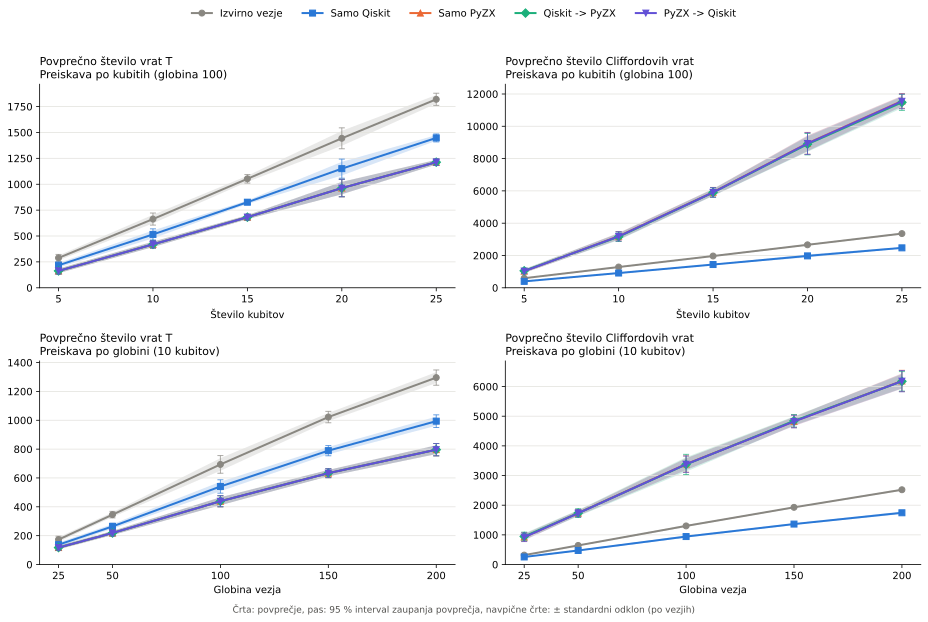

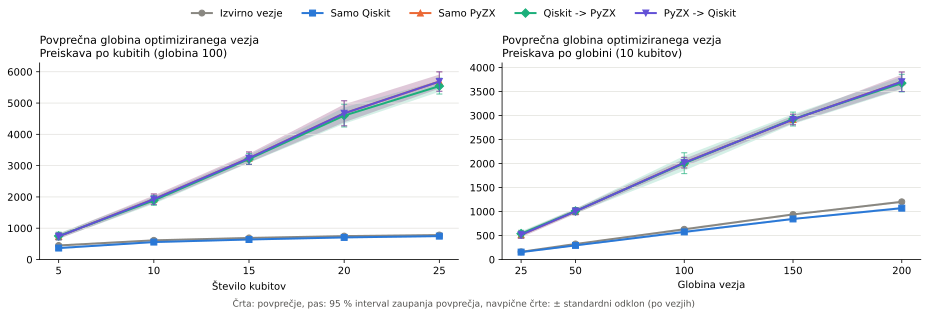

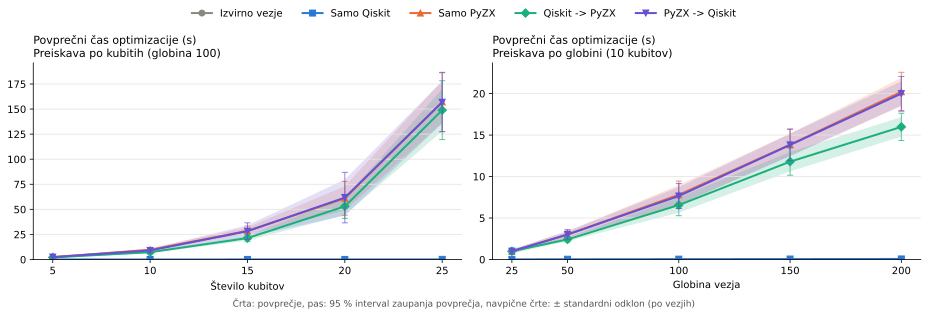

Grafi shranjeni v graphs


In [24]:
sweeps = [("qubits", benchmark_qubit_counts, "Število kubitov", f"Preiskava po kubitih (globina {benchmark_depth})"),
          ("depth", depth_sweep_depths, "Globina vezja", f"Preiskava po globini ({depth_sweep_qubits} kubitov)")]
graphs_dir = "graphs"
os.makedirs(graphs_dir, exist_ok=True)


def draw_metric(ax, sweep, xs, xlabel, title, metric):
    for method in display_names:
        if metric in optimizer_only and method == "Original":
            # izvirno vezje nima časa optimizacije (prazna črta samo za legendo)
            ax.plot([], [], color=colors[method], marker=markers[method], markersize=6, linewidth=2,
                    label=display_names[method])
            continue
        draw_series(ax, sweep, xs, metric, method)
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel(xlabel)
    ax.set_xticks(xs)
    ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_ylim(bottom=0)


def plot_columns(columns: list, file: str, horizontal: bool = False):
    n_rows, n_cols = (len(columns), len(sweeps)) if horizontal else (len(sweeps), len(columns))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6.5 * n_cols, 4.2 * n_rows), squeeze=False)

    for s, (sweep, xs, xlabel, sweep_title) in enumerate(sweeps):
        for c, (title, metric) in enumerate(columns):
            ax = axes[c, s] if horizontal else axes[s, c]
            draw_metric(ax, sweep, xs, xlabel, f"{title}\n{sweep_title}", metric)

    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=len(labels), frameon=False)
    fig.tight_layout(rect=(0, 0, 1, 0.93))
    fig.text(0.5, -0.01, error_note, ha="center", fontsize=9, color="#52514e")

    fig.savefig(os.path.join(graphs_dir, file), dpi=150, bbox_inches="tight")
    plt.show()


t_count_column = ("Povprečno število vrat T", "t_count")
clifford_column = ("Povprečno število Cliffordovih vrat", "clifford_gates")
depth_column = ("Povprečna globina optimiziranega vezja", "circuit_depth")
time_column = ("Povprečni čas optimizacije (s)", "time_s")

plot_columns([t_count_column, clifford_column], "graph_gates.png")
plot_columns([depth_column], "graph_circuit_depth.png", horizontal=True)
plot_columns([time_column], "graph_time.png", horizontal=True)
print(f"Grafi shranjeni v {graphs_dir}")